In [5]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

pd.options.display.max_columns = 500

### Загрузим датасет с машинами. Цель - верно восстанавливать для каждой из них цену продажи!

In [28]:
data = pd.read_csv('autos.csv')

data.head()

,name,year,selling_price,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,60000,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,135000,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,600000,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,250000,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,450000,141000,Diesel,Individual,Manual,Second Owner


In [29]:
### Колонка с тергетом - "selling price"

X = data.drop("selling_price", axis=1)
y = data["selling_price"]

### Будем замерять MSLE!
### Поэтому прологарифмируем таргет
### А после оптимизируем MSE

y = y.apply(np.log1p)

In [30]:
### Разделим выборку на трейн и тест!

from sklearn.model_selection import train_test_split 

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=1)

__Задание__ 

Реализуйте свой MeanTargetEncoder с добавленем некоторого шума!

Однажды в лекционном материале, обсуждая счетчики, мы говорили с вами о том, что из-за них модели могут переобучаться. Один из способов бороться с этим - валидировать расчеты среднего таргета (стратегия отложенной выборки / расчеты на кросс-валидации). Но есть еще проще!

Можно просто к значению счетчика добавить случайный шум (зашумить данные)!

Напомним, что рассчитываться новые признаки должны по такой формуле:

$$
g_j = \frac{\sum_{i=1}^{l} [f_j(x) = f_j(x_i)]}{l} + C * \epsilon
$$



Пусть шум будет случайной величиной из нормального стандартного распределения, то есть $\epsilon \sim N(0, 1) $, а $ C = 0.006$.

Создавая свой класс-трансформер, наследуйтесь от классов `BaseEstimator, TransformerMixin` из `sklearn.base`. Трансформер не должен модифицировать передаваемую ему выборку inplace, а все необходимые статистики нужно считать только по обучающей выборке в методе `fit`. Ваш трансформер должен принимать при инициализации список из категориальных признаков и список из числовых признаков. 

Если для какого-то признака в тестовой выборке отсутствует значение, трансформер должен поставить там 0.

На выходе должен получиться датасет того же размера с измененными категориальными признаками.

Класс MeanTargetEncoderNoise должен иметь следующую сигнатуру:



In [ ]:


from sklearn.base import BaseEstimator, TransformerMixin

class MeanTargetEncoderNoise(BaseEstimator, TransformerMixin):
    
    def __init__(self, categorical, numeric):
        
        ### Your code is here
        
        self.categorical = categorical
        self.numeric = numeric
    
    def fit(self, X, y):
        ### Your code is here
        
        def noisy_mean(x):
            return np.mean(x) + 0.006 * np.random.normal()
        
        self.categorical_counters = X[self.categorical].apply(
        lambda col: y.groupby(col).apply(noisy_mean).to_dict()
        ).to_dict()
        
        return self
        
    def transform(self, df):
        ### Your code is here
        temp = df.copy()
        
        for feature, replace_dict in self.categorical_counters.items():
            temp.loc[
                ~temp[feature].isin(replace_dict.keys()), feature
            ] = 0
            temp[feature] = temp[feature].replace(replace_dict)
        return temp



Разделите колонки на вещественные и категориальные. Приведите все категориальные колонки к типу `object`.

Далее применим наш кодировщик к `X_train, X_test`, так же как например мы применяем `StandardScaler`, чтобы проверить работоспособность нашего класса. Установите зерно датчика случайный чисел `np.random.seed(1)`.

После того, как вы изменили обучающую и тестовую выборки, сохраните первые 10 строк полученного промежуточного датафрейма обучающей выборки (`X_train`) в файл в формате csv с сепаратором `;`. Не забудьте индекс. Отправьте полученный файл в форму ниже.

Список колонок которые должны быть в файле для сдачи:
```py
cols = [
    "km_driven",
    "name",
    "year",
    "fuel",
    "seller_type",
    "transmission",
    "owner"
]
```

### Ваше решение


Разделение колонок на категориальные и числовые.

In [31]:
object_cols = ['name', 'year', 'fuel', 'seller_type', 'transmission', 'owner']
num_cols = ['km_driven']

X.head()

,name,year,km_driven,fuel,seller_type,transmission,owner
0,Maruti 800 AC,2007,70000,Petrol,Individual,Manual,First Owner
1,Maruti Wagon R LXI Minor,2007,50000,Petrol,Individual,Manual,First Owner
2,Hyundai Verna 1.6 SX,2012,100000,Diesel,Individual,Manual,First Owner
3,Datsun RediGO T Option,2017,46000,Petrol,Individual,Manual,First Owner
4,Honda Amaze VX i-DTEC,2014,141000,Diesel,Individual,Manual,Second Owner


Реализация класса MeanTargetEncoderNoise.

In [32]:


from sklearn.base import BaseEstimator, TransformerMixin

class MeanTargetEncoderNoise(BaseEstimator, TransformerMixin):
    
    def __init__(self, categorical, numeric):
        
        ### Your code is here
        
        self.categorical = categorical
        self.numeric = numeric
    
    def fit(self, X, y):
        ### Your code is here
        
        def noisy_mean(x):
            return np.mean(x) + 0.006 * np.random.normal()
        
        self.categorical_counters = X[self.categorical].apply(
        lambda col: y.groupby(col).apply(noisy_mean).to_dict()
        ).to_dict()
        
        return self
        
    def transform(self, df):
        ### Your code is here
        temp = df.copy()
        
        for feature, replace_dict in self.categorical_counters.items():
            temp.loc[
                ~temp[feature].isin(replace_dict.keys()), feature
            ] = 0
            temp[feature] = temp[feature].replace(replace_dict)
        return temp



Проверка работы трансформера.

In [35]:


np.random.seed(1)
transformer = MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)

transformer.fit(X_train, y_train)

train = transformer.transform(X_train)
test = transformer.transform(X_test)

train.head(10)

print(train.dtypes)

name            float64
year            float64
km_driven         int64
fuel            float64
seller_type     float64
transmission    float64
owner           float64
dtype: object


/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

In [34]:
train.head(10).to_csv('train.csv', sep=';', index=False)

Обучите несколько деревьев, перебирая максимальную глубину алгоритма из списка `max_depth_list`, а остальные параметры оставьте дефолтными. Выведите лучшее значение гиперпараметра. Постройте график зависимости MSLE на тестовой выборке от значения гиперпараметра. Воспользуйтесь `Pipeline` без `GridSearch`. Проделайте то же самое с `min_samples_split`, `min_impurity_decrease`, `max_leaf_nodes`. (по 2б на каждый параметр)

In [36]:
max_depth_list = [3, 5, 8, 12]
min_samples_split_list = [10, 50, 100, 500]
min_impurity_decrease_list = [0, 0.1, 0.15, 0.2]
max_leaf_nodes_list = [100, 200, 500]

In [42]:
from sklearn.metrics import mean_squared_error as mse
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

np.random.seed(1)
### Your code is here
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline

max_depth_list = [1,2,3,4, 5, 8, 12]
result_test = {}
result_train = {}
for col in max_depth_list:
    pipe = Pipeline([("custom_transformer",
                   MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
                  
                  
                 ("decision_tree", 
                  DecisionTreeRegressor(max_depth=col))])

    pipe.fit(X_train, y_train)

    mse_train =mse(y_train, pipe.predict(X_train))
    mse_test = mse(y_test, pipe.predict(X_test))
    max_depth = f'max_depth_{col}'
    result_test.update({max_depth:mse_test})
    result_train.update({max_depth:mse_train})

result_test


/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

{'max_depth_1': 0.5229485887238029,
 'max_depth_2': 0.6165651851474382,
 'max_depth_3': 0.7969558657595327,
 'max_depth_4': 0.9550214084479794,
 'max_depth_5': 1.4419709974404638,
 'max_depth_8': 1.9882136454189445,
 'max_depth_12': 1.9823688707271658}

In [47]:
from sklearn.metrics import mean_squared_error
from sklearn.metrics import mean_squared_log_error
def find_best_hyperparameter(hyperparameter_name, hyperparameter_values, X_train, y_train, X_test, y_test):
    msle_scores = []
    mse_scores = []  # Добавляем список для сохранения MSE

    for value in hyperparameter_values:
        pipeline = Pipeline([
            ('encoder', MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
            ('model', DecisionTreeRegressor(**{hyperparameter_name: value}))
        ])

        pipeline.fit(X_train, y_train)
        y_pred = pipeline.predict(X_test)
        
        # Сохраняем метрики для текущего гиперпараметра
        msle_test = mean_squared_log_error(y_test, y_pred)
        mse_test = mean_squared_error(y_test, y_pred)
        
        msle_scores.append(msle_test)
        mse_scores.append(mse_test)  # Сохраняем MSE
        
        # Вывод информации
        print(f"Значение {hyperparameter_name}: {value}")
        print(f"MSLE на тесте: {round(msle_test, 3)}")
        print(f"MSE на тесте: {round(mse_test, 3)}\n")

    # Поиск лучшего значения по MSE
    best_value_idx = np.argmin(mse_scores)
    best_value = hyperparameter_values[best_value_idx]
    
    # Построение графиков для обеих метрик
    plt.figure(figsize=(12, 5))
    
    plt.subplot(1, 2, 1)
    plt.plot(hyperparameter_values, msle_scores, 'o-')
    plt.xlabel(hyperparameter_name)
    plt.ylabel('MSLE')
    plt.title(f'MSLE vs {hyperparameter_name}')
    
    plt.subplot(1, 2, 2)
    plt.plot(hyperparameter_values, mse_scores, 'o-', color='orange')
    plt.xlabel(hyperparameter_name)
    plt.ylabel('MSE')
    plt.title(f'MSE vs {hyperparameter_name}')
    
    plt.tight_layout()
    plt.show()

    # Вывод итоговых результатов
    print(f"Лучшее значение {hyperparameter_name} (по MSE): {best_value}")
    print(f"Лучший MSE: {round(min(mse_scores), 3)}")
    print(f"Соответствующий MSLE: {round(msle_scores[best_value_idx], 3)}")

    return best_value

/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_depth: 1
MSLE на тесте: 0.003
MSE на тесте: 0.519



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_depth: 2
MSLE на тесте: 0.003
MSE на тесте: 0.617



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_depth: 3
MSLE на тесте: 0.004
MSE на тесте: 0.797



... (4 outputs left out)

/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_depth: 8
MSLE на тесте: 0.013
MSE на тесте: 1.988



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_depth: 12
MSLE на тесте: 0.013
MSE на тесте: 1.985



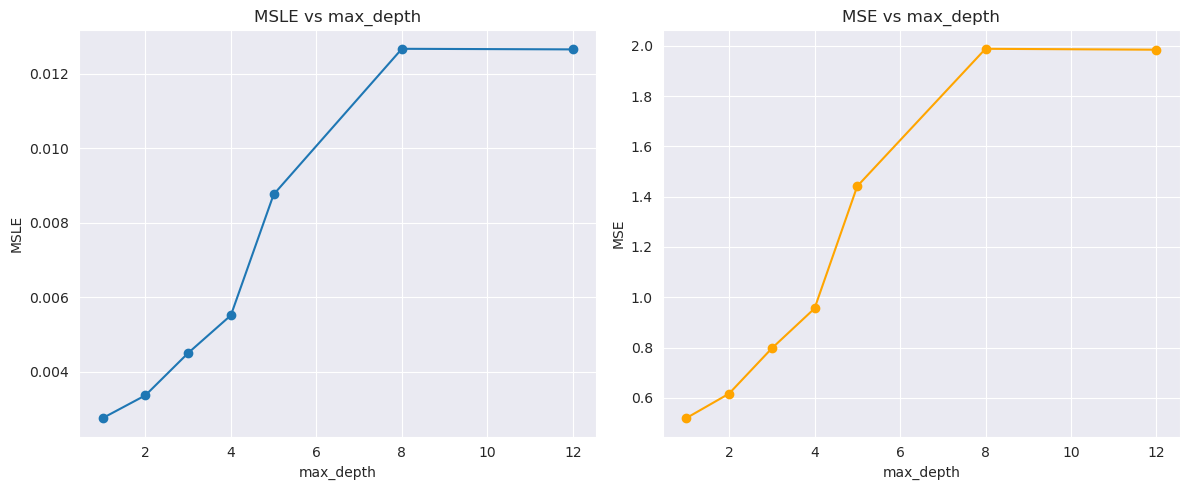

Лучшее значение max_depth (по MSE): 1
Лучший MSE: 0.519
Соответствующий MSLE: 0.003


In [48]:
best_max_depth = find_best_hyperparameter('max_depth', max_depth_list, X_train, y_train, X_test, y_test)

/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_samples_split: 10
MSLE на тесте: 0.009
MSE на тесте: 1.432



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_samples_split: 50
MSLE на тесте: 0.009
MSE на тесте: 1.438



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_samples_split: 100
MSLE на тесте: 0.005
MSE на тесте: 0.953



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_samples_split: 500
MSLE на тесте: 0.005
MSE на тесте: 0.808



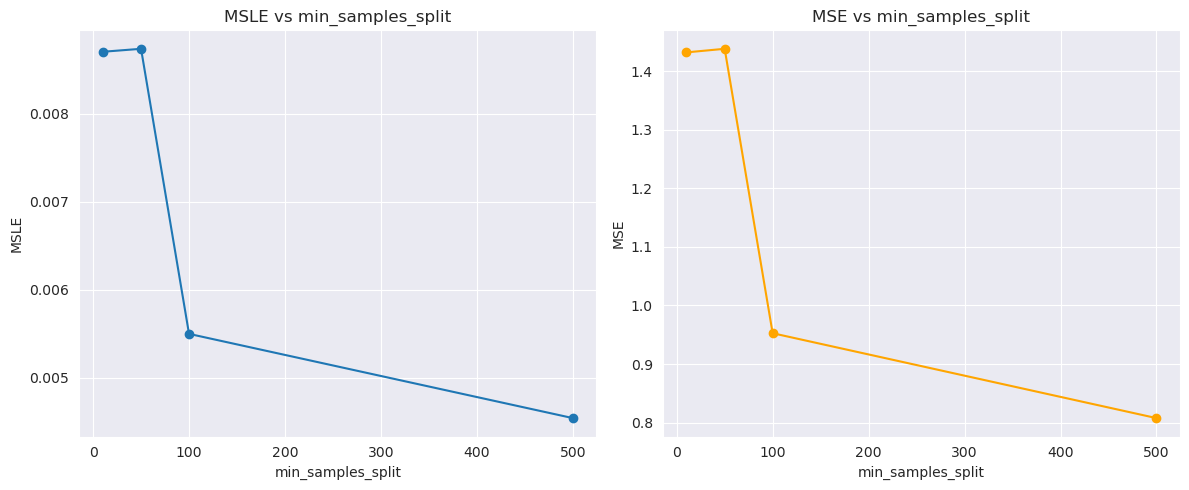

Лучшее значение min_samples_split (по MSE): 500
Лучший MSE: 0.808
Соответствующий MSLE: 0.005


In [49]:
best_min_samples_split = find_best_hyperparameter('min_samples_split', min_samples_split_list, X_train, y_train, X_test, y_test)

/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0
MSLE на тесте: 0.013
MSE на тесте: 1.986



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0.1
MSLE на тесте: 0.003
MSE на тесте: 0.52



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0.15
MSLE на тесте: 0.003
MSE на тесте: 0.519



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0.2
MSLE на тесте: 0.003
MSE на тесте: 0.522



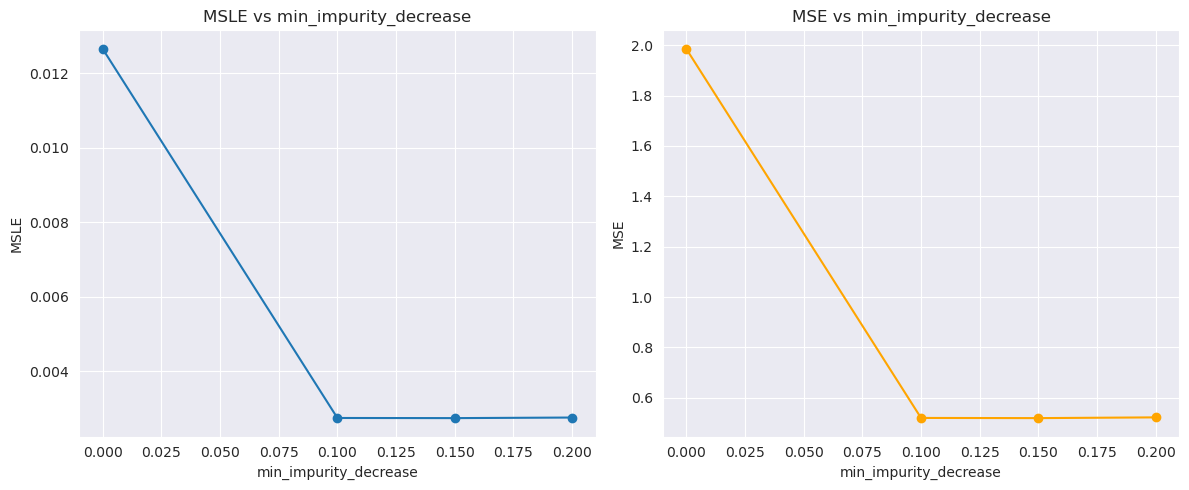

Лучшее значение min_impurity_decrease (по MSE): 0.15
Лучший MSE: 0.519
Соответствующий MSLE: 0.003


In [50]:
est_min_impurity_decrease = find_best_hyperparameter('min_impurity_decrease', min_impurity_decrease_list, X_train, y_train, X_test, y_test)

/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_leaf_nodes: 100
MSLE на тесте: 0.013
MSE на тесте: 1.99



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_leaf_nodes: 200
MSLE на тесте: 0.013
MSE на тесте: 1.986



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение max_leaf_nodes: 500
MSLE на тесте: 0.013
MSE на тесте: 1.985



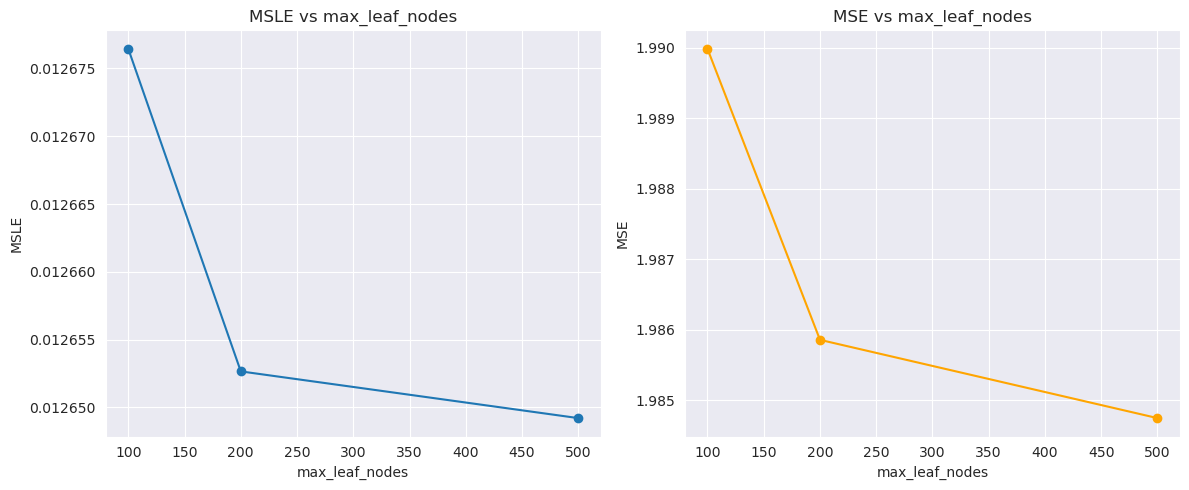

Лучшее значение max_leaf_nodes (по MSE): 500
Лучший MSE: 1.985
Соответствующий MSLE: 0.013


In [51]:
best_max_leaf_nodes = find_best_hyperparameter('max_leaf_nodes', max_leaf_nodes_list, X_train, y_train, X_test, y_test)

/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0
MSLE на тесте: 0.013
MSE на тесте: 1.988



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0.1
MSLE на тесте: 0.003
MSE на тесте: 0.52



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0.15
MSLE на тесте: 0.003
MSE на тесте: 0.52



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Значение min_impurity_decrease: 0.2
MSLE на тесте: 0.003
MSE на тесте: 0.52



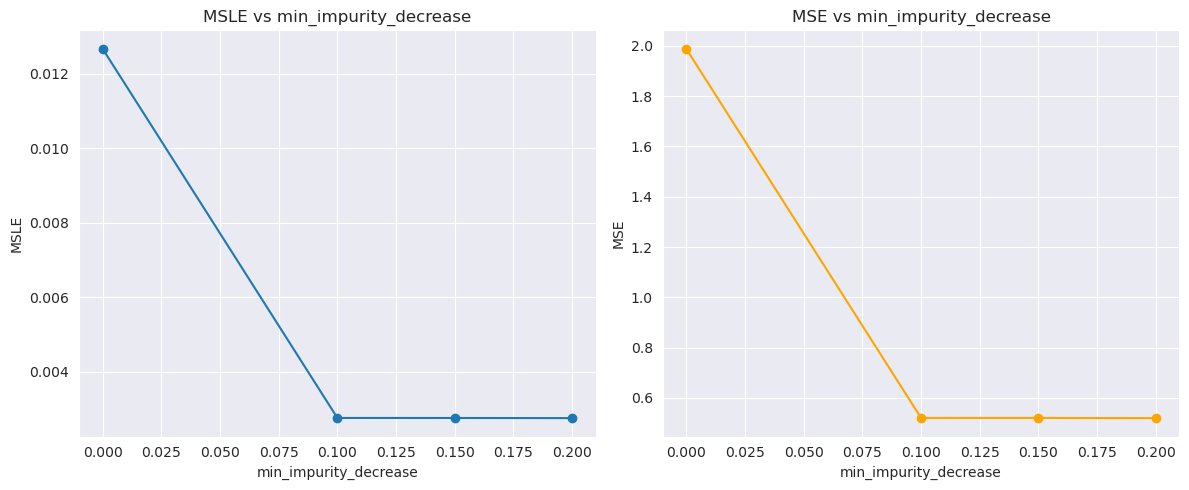

Лучшее значение min_impurity_decrease (по MSE): 0.2
Лучший MSE: 0.52
Соответствующий MSLE: 0.003


In [52]:
best_min_impurity_decrease = find_best_hyperparameter('min_impurity_decrease', min_impurity_decrease_list, X_train, y_train, X_test, y_test)

In [53]:


from sklearn.metrics import mean_squared_log_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

np.random.seed(1)

pipe = Pipeline([
    ("encoder", MeanTargetEncoderNoise(categorical=object_cols, numeric=num_cols)),
    ("model", DecisionTreeRegressor(max_depth=best_max_depth, min_samples_split=best_min_samples_split, min_impurity_decrease=best_min_impurity_decrease, max_leaf_nodes=best_max_leaf_nodes))
])

pipe.fit(X_train, y_train)

print(f"MSLE на тесте: {round(mean_squared_log_error(y_test, pipe.predict(X_test)), 3)}")
print(f"MSE на тесте: {round(mse(y_test, pipe.predict(X_test)), 3)}")



/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

MSLE на тесте: 0.003
MSE на тесте: 0.523


/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `

Подберите лучшую комбинацию параметров, используя `GridSearchCV` и набор массивов значений параметров из предыдущего задания. Для лучшей комбинации посчитайте MSLE на тестовой выборке. Получились ли лучшие параметры такими же, как если бы вы подбирали их по-отдельности при остальных гиперпараметрах по умолчанию (предыдущее задание)? (2б)

In [54]:
from sklearn.metrics import mean_squared_log_error
from sklearn.tree import DecisionTreeRegressor
from sklearn.pipeline import Pipeline
from sklearn.model_selection import GridSearchCV

np.random.seed(1)

param_grid = {
    "model__max_depth": [3, 5, 8, 12],
    "model__min_samples_split": [10, 50, 100, 500],
    "model__min_impurity_decrease": [0, 0.1, 0.15, 0.2],
    "model__max_leaf_nodes": [100, 200, 500]
}

np.random.seed(1)

grid_search = GridSearchCV(pipe, param_grid, cv=5, scoring="neg_mean_squared_log_error", n_jobs=-1)
grid_search.fit(X_train, y_train)

best_params = grid_search.best_params_
print(f"Лучшие параметры: {best_params}")

print(f"MSLE на тесте: {round(mean_squared_log_error(y_test, grid_search.predict(X_test)), 3)}")
print(f"MSE на тесте: {round(mse(y_test, grid_search.predict(X_test)), 3)}")

/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: D

Лучшие параметры: {'model__max_depth': 12, 'model__max_leaf_nodes': 200, 'model__min_impurity_decrease': 0.2, 'model__min_samples_split': 500}
MSLE на тесте: 0.003
MSE на тесте: 0.523


/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  temp[feature] = temp[feature].replace(replace_dict)
/tmp/ipykernel_68634/1554491251.py:32: FutureWarning: Downcasting behavior in `replace` is deprecated and will be removed in a future version. To retain the old behavior, explicitly call `result.infer_objects(copy=False)`. To opt-in to the future behavior, set `